# Разведочный анализ данных: Default of Credit Card Clients

Данные: 30 000 клиентов кредитных карт тайваньского банка, апрель–сентябрь 2005 года
([UCI](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)).
Таргет `default.payment.next.month` показывает, допустил ли клиент дефолт в октябре.

В этом ноутбуке я разбираюсь с данными до построения пайплайна. По итогам нужно решить:
- какие правила проверки данных заложить в Great Expectations;
- что чистить и как обращаться со странными кодами;
- какие признаки стоит сконструировать;
- какие метрики и какой способ разбиения подходят под баланс классов.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))
from src.features.build_features import build_features  # noqa: E402

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
FIG_DIR = ROOT / "reports" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "default"
df = pd.read_csv(ROOT / "data/raw/UCI_Credit_Card.csv").rename(
    columns={"default.payment.next.month": TARGET}
)
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## 1. Общая информация

In [2]:
print("Размер:", df.shape)
print("Пропусков:", df.isna().sum().sum())
print("Уникальных ID:", df["ID"].nunique())
print("Полных дубликатов без учёта ID:", df.drop(columns="ID").duplicated().sum())
df.dtypes.value_counts()

Размер: (30000, 25)
Пропусков: 0
Уникальных ID: 30000
Полных дубликатов без учёта ID: 35


float64    13
int64      12
Name: count, dtype: int64

In [3]:
df.describe().T[["mean", "std", "min", "50%", "max"]].round(1)

,mean,std,min,50%,max
ID,15000.5,8660.4,1.0,15000.5,30000.0
LIMIT_BAL,167484.3,129747.7,10000.0,140000.0,1000000.0
SEX,1.6,0.5,1.0,2.0,2.0
EDUCATION,1.9,0.8,0.0,2.0,6.0
MARRIAGE,1.6,0.5,0.0,2.0,3.0
AGE,35.5,9.2,21.0,34.0,79.0
PAY_0,-0.0,1.1,-2.0,0.0,8.0
PAY_2,-0.1,1.2,-2.0,0.0,8.0
PAY_3,-0.2,1.2,-2.0,0.0,8.0
PAY_4,-0.2,1.2,-2.0,0.0,8.0


Пропусков нет. Суммы (`LIMIT_BAL`, `BILL_AMT*`, `PAY_AMT*`) записаны как float, хотя дробной
части нигде нет, поэтому при подготовке привожу их к int.

Без учёта `ID` в данных 35 полностью одинаковых строк. Скорее всего, это разные клиенты с
одинаковым профилем, например с нулевой активностью. Но если такая пара разъедется по
train и test, модель будет «узнавать» тестовые примеры. Строк немного, поэтому я оставляю
одну копию из каждой пары.

Отрицательные `BILL_AMT` (около 2% клиентов в сентябре) похожи на переплату по карте: клиент
внёс больше, чем был должен. Это нормальная ситуация, и такие строки я не удаляю.

## 2. Целевая переменная

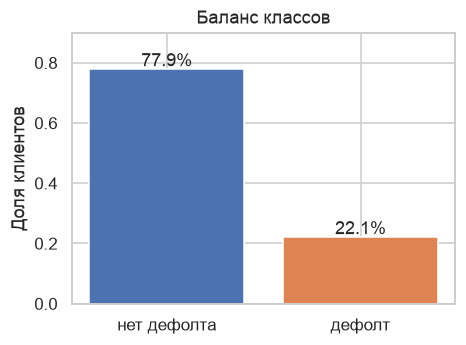

In [4]:
share = df[TARGET].value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(["нет дефолта", "дефолт"], share.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(share.values):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
ax.set(ylabel="Доля клиентов", ylim=(0, 0.9), title="Баланс классов")
plt.show()

Дефолтов 22%. Дисбаланс умеренный, oversampling не нужен, но он влияет на выбор метрик и порога:
- разбиение train/test стратифицированное, иначе доли в выборках могут разъехаться;
- главная метрика ROC-AUC (и Gini = 2·AUC − 1, как принято в скоринге), она не зависит от порога;
- порог 0.5 для такого баланса слишком высокий, его надо подбирать отдельно (на CV, не на test).

## 3. Категориальные признаки и недокументированные коды

In [5]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    stats = df.groupby(col)[TARGET].agg(clients="size", default_rate="mean")
    print(stats.round(3).T.to_string(), end="\n\n")

SEX                   1          2
clients       11888.000  18112.000
default_rate      0.242      0.208

EDUCATION        0          1          2         3        4        5       6
clients       14.0  10585.000  14030.000  4917.000  123.000  280.000  51.000
default_rate   0.0      0.192      0.237     0.252    0.057    0.064   0.157

MARRIAGE           0          1          2       3
clients       54.000  13659.000  15964.000  323.00
default_rate   0.093      0.235      0.209    0.26



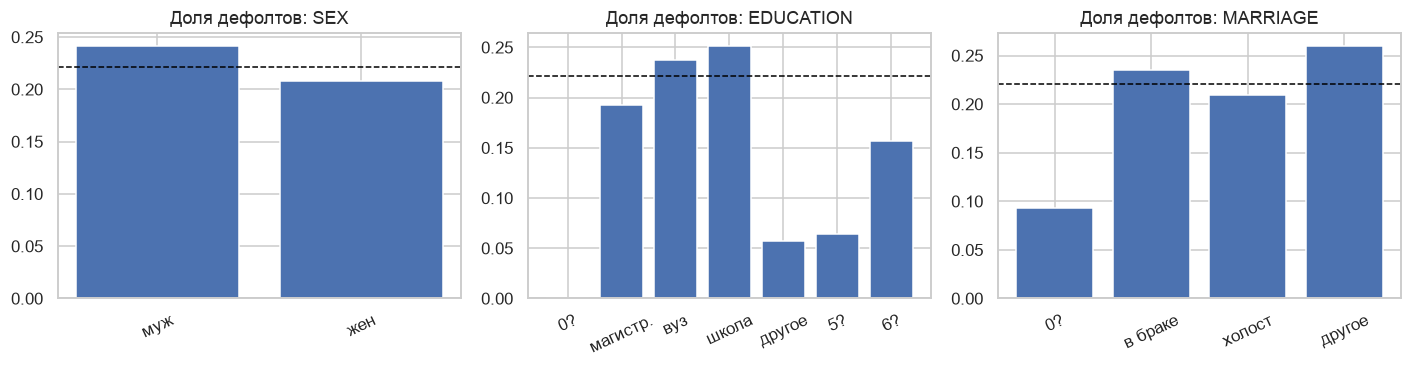

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
labels = {
    "SEX": {1: "муж", 2: "жен"},
    "EDUCATION": {0: "0?", 1: "магистр.", 2: "вуз", 3: "школа", 4: "другое", 5: "5?", 6: "6?"},
    "MARRIAGE": {0: "0?", 1: "в браке", 2: "холост", 3: "другое"},
}
for ax, col in zip(axes, labels):
    rate = df.groupby(col)[TARGET].mean()
    ax.bar([labels[col][k] for k in rate.index], rate.values)
    ax.axhline(df[TARGET].mean(), color="black", ls="--", lw=1)
    ax.set_title(f"Доля дефолтов: {col}")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

По описанию датасета `EDUCATION` принимает значения 1–4, а `MARRIAGE` 1–3. В данных есть ещё
`EDUCATION` = 0, 5, 6 (345 клиентов) и `MARRIAGE` = 0 (54 клиента). Что они значат, неизвестно.
Дефолтов в этих группах заметно меньше среднего, но они слишком маленькие, чтобы держать их
отдельными категориями. В пайплайне (`normalize_categories`) я свожу их к «другое».

В правилах Great Expectations эти коды при этом **разрешены**: они реально есть в источнике.
Правило должно срабатывать на коды, которых раньше не было.

Мужчины дефолтят чуть чаще (24.2% против 20.8%). Отмечу отдельно: в настоящем банке пол как
признак кредитной модели, скорее всего, пришлось бы убрать из-за требований
недискриминации. В учебной задаче я его оставляю: признак есть в данных и в примере API из задания.

## 4. Возраст и кредитный лимит

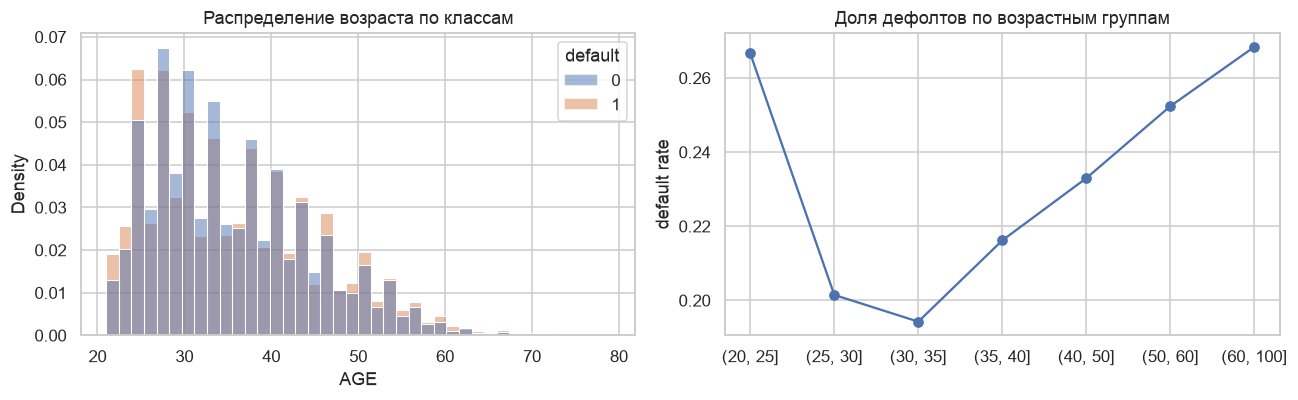

AGE,"(20, 25]","(25, 30]","(30, 35]","(35, 40]","(40, 50]","(50, 60]","(60, 100]"
mean,0.267,0.201,0.194,0.216,0.233,0.252,0.268
size,3871.000,7142.000,5796.000,4917.000,6005.000,1997.000,272.000


In [7]:
age_bins = [20, 25, 30, 35, 40, 50, 60, 100]
by_age = df.groupby(pd.cut(df["AGE"], age_bins), observed=True)[TARGET].agg(["mean", "size"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(data=df, x="AGE", hue=TARGET, bins=40, stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Распределение возраста по классам")
axes[1].plot(by_age.index.astype(str), by_age["mean"], marker="o")
axes[1].set(title="Доля дефолтов по возрастным группам", ylabel="default rate")
plt.tight_layout()
plt.show()
by_age.round(3).T

Зависимость от возраста U-образная: молодые (21–25) и старшие (50+) дефолтят чаще, минимум
приходится на 26–35 лет. Линейная модель такую форму по сырому `AGE` не поймает, поэтому я
добавляю категориальный `AGE_BIN` с этими же границами (они вынесены в `params.yaml`).

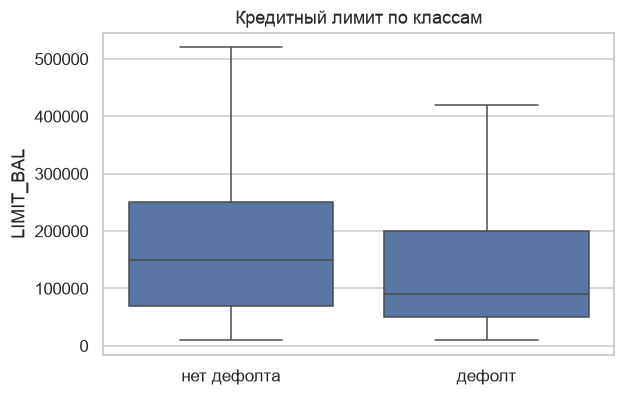

default
0    150000.0
1     90000.0
Name: LIMIT_BAL, dtype: float64

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.8))
sns.boxplot(data=df, x=TARGET, y="LIMIT_BAL", showfliers=False, ax=ax)
ax.set_xticks([0, 1], ["нет дефолта", "дефолт"])
ax.set(xlabel="", title="Кредитный лимит по классам")
plt.show()
df.groupby(TARGET)["LIMIT_BAL"].median()

У дефолтных клиентов медианный лимит 90 тыс. NT$, у остальных 150 тыс. Банк, судя по всему,
уже выдаёт более надёжным клиентам большие лимиты, так что `LIMIT_BAL` сам несёт информацию
о риске. Кроме того, это естественный знаменатель для относительных признаков (загрузка лимита).

## 5. История платежей PAY_x — самый сильный сигнал

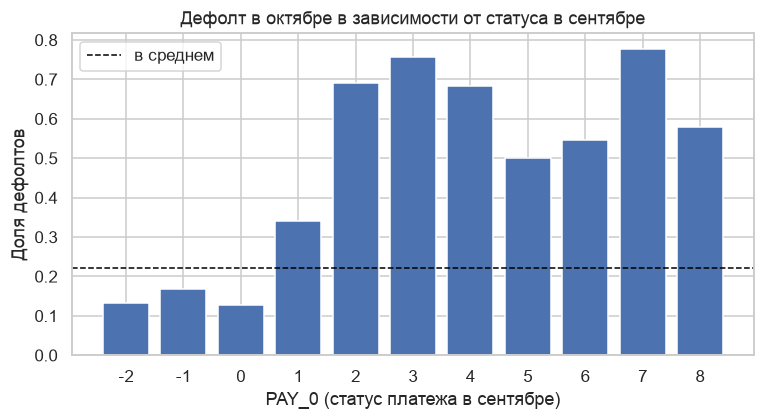

PAY_0,-2,-1,0,1,2,3,4,5,6,7,8
clients,2759.000,5686.000,14737.000,3688.000,2667.000,322.000,76.000,26.0,11.000,9.000,19.000
default_rate,0.132,0.168,0.128,0.339,0.691,0.758,0.684,0.5,0.545,0.778,0.579


In [9]:
pay0 = df.groupby("PAY_0")[TARGET].agg(clients="size", default_rate="mean")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(pay0.index.astype(str), pay0["default_rate"])
ax.axhline(df[TARGET].mean(), color="black", ls="--", lw=1, label="в среднем")
ax.set(xlabel="PAY_0 (статус платежа в сентябре)", ylabel="Доля дефолтов",
       title="Дефолт в октябре в зависимости от статуса в сентябре")
ax.legend()
fig.savefig(FIG_DIR / "default_rate_by_pay0.png", bbox_inches="tight")
plt.show()
pay0.round(3).T

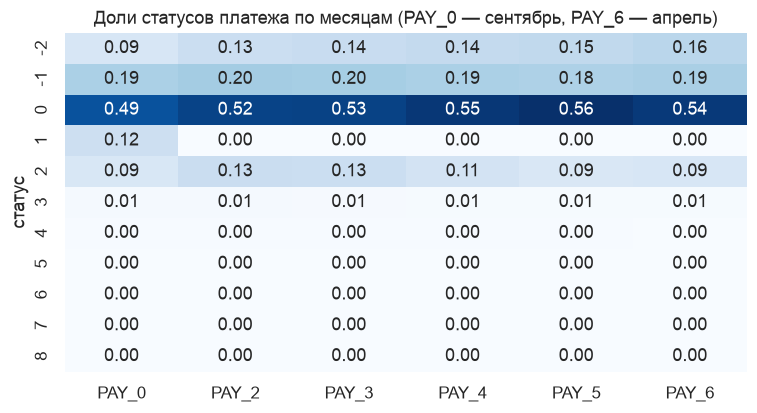

In [10]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
status_share = df[pay_cols].apply(lambda s: s.value_counts(normalize=True)).fillna(0)
plt.figure(figsize=(8, 4))
sns.heatmap(status_share, annot=True, fmt=".2f", cmap="Blues", cbar=False)
plt.title("Доли статусов платежа по месяцам (PAY_0 — сентябрь, PAY_6 — апрель)")
plt.ylabel("статус")
plt.show()

Расшифровка статусов: −2 — картой не пользовался, −1 — погасил полностью, 0 — внёс минимальный
платёж (револьверный долг), 1…8 — просрочка на столько месяцев.

- Пока просрочки нет (−2, −1, 0), дефолтят 13–17% клиентов. Уже при PAY_0 = 1 доля вырастает до 34%,
  а при 2 — до 69%. Это главный признак модели.
- Отношение к риску у PAY_x не монотонное: «−1» хуже, чем «0». Линейной модели это мешает,
  деревьям нет.
- В PAY_2…PAY_6 значение 1 почти не встречается (в PAY_2 — 28 раз на 30 тысяч), сразу идёт 2.
  Похоже на особенность кодирования в источнике, которую стоит иметь в виду.

Из истории за 6 месяцев я строю агрегаты: максимальную просрочку, число месяцев с просрочкой,
число месяцев «не пользовался» и «погасил полностью».

## 6. Суммы счетов и платежей

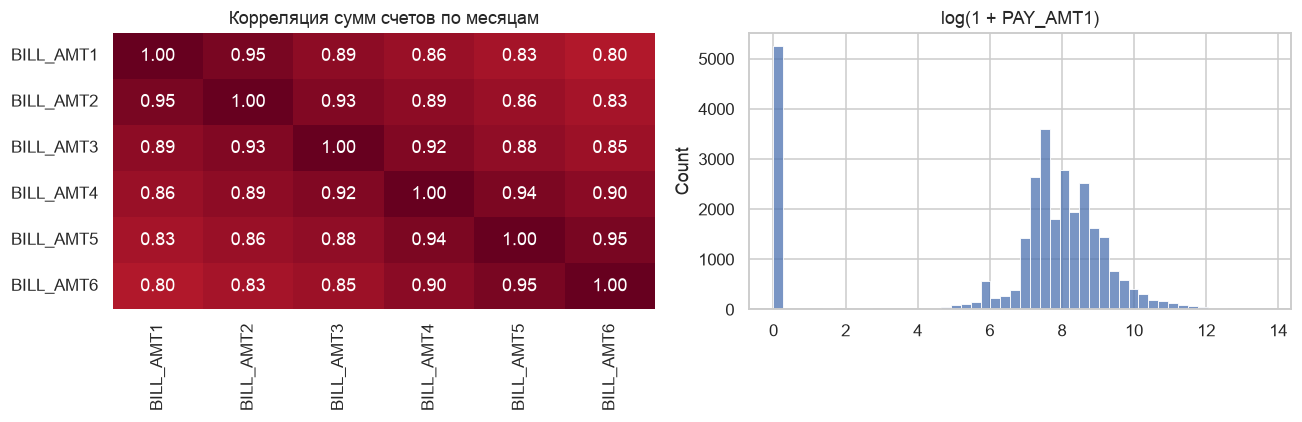

Асимметрия: {'LIMIT_BAL': 1.0, 'BILL_AMT1': 2.7, 'PAY_AMT1': 14.7}
Доля нулевых платежей в сентябре: 0.175


In [11]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(df[bill_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            ax=axes[0], cbar=False)
axes[0].set_title("Корреляция сумм счетов по месяцам")
sns.histplot(np.log1p(df["PAY_AMT1"]), bins=50, ax=axes[1])
axes[1].set(title="log(1 + PAY_AMT1)", xlabel="")
plt.tight_layout()
plt.show()
print("Асимметрия:", df[["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]].skew().round(1).to_dict())
print("Доля нулевых платежей в сентябре:", round((df["PAY_AMT1"] == 0).mean(), 3))

- Счета за соседние месяцы коррелируют на 0.8–0.95. По отдельности шесть колонок `BILL_AMT`
  почти ничего не добавляют (IV ≈ 0.01, см. ниже), потому что сама сумма долга без масштаба
  (лимита) мало о чём говорит.
- У сумм очень длинные хвосты (асимметрия `PAY_AMT1` ≈ 15). Для логистической регрессии
  нужен `StandardScaler`, деревья к этому нечувствительны.

Поэтому я добавляю относительные признаки: загрузку лимита (`UTIL_*` = счёт / лимит), тренд
задолженности за полгода и долю погашения (`PAY_TO_BILL_RATIO`). В последнем платёж месяца t
сопоставляется со счётом месяца t−1: сентябрьский платёж гасит августовскую выписку.

## 7. Проверка сконструированных признаков

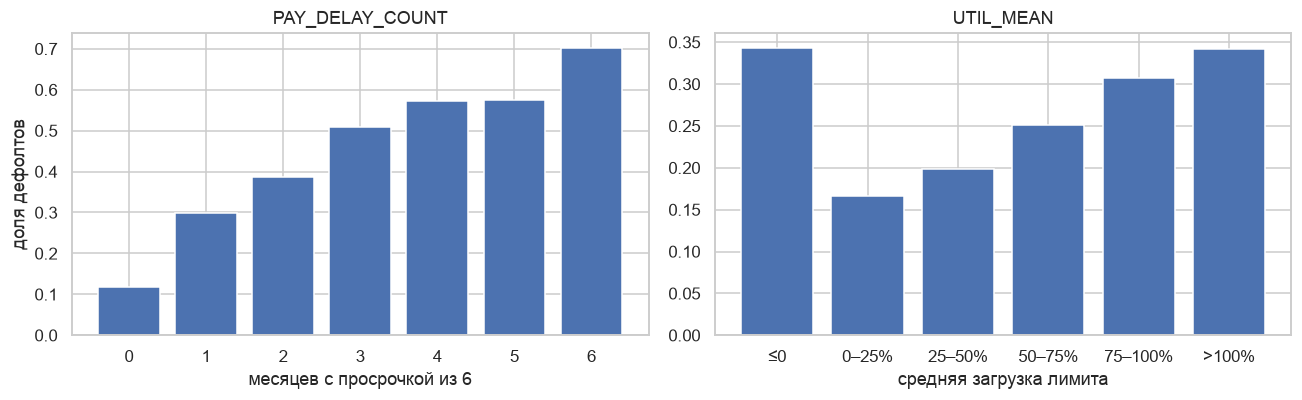

In [12]:
fe = build_features(df)
fe[TARGET] = df[TARGET]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
by_cnt = fe.groupby("PAY_DELAY_COUNT")[TARGET].mean()
axes[0].bar(by_cnt.index.astype(str), by_cnt.values)
axes[0].set(xlabel="месяцев с просрочкой из 6", ylabel="доля дефолтов", title="PAY_DELAY_COUNT")

util = pd.cut(fe["UTIL_MEAN"], [-np.inf, 0, 0.25, 0.5, 0.75, 1, np.inf],
              labels=["≤0", "0–25%", "25–50%", "50–75%", "75–100%", ">100%"])
by_util = fe.groupby(util, observed=True)[TARGET].mean()
axes[1].bar(by_util.index.astype(str), by_util.values)
axes[1].set(xlabel="средняя загрузка лимита", title="UTIL_MEAN")
plt.tight_layout()
plt.show()

- Доля дефолтов растёт с числом месяцев просрочки почти монотонно: от 12% у клиентов без
  просрочек до 70% у тех, кто был в просрочке все 6 месяцев.
- По загрузке лимита картина снова U-образная. Риск высокий на обоих краях: у клиентов,
  которые выбрали лимит полностью (больше 100%: 34% дефолтов), и, неожиданно, у клиентов
  с нулевым или отрицательным балансом (тоже 34%). Видимо, во вторую группу попадают
  клиенты, которые перестали пользоваться картой.

## 8. Information Value

В кредитном скоринге силу признака принято оценивать через Information Value (IV):
считаем WoE по бинам и суммируем. Ориентиры: < 0.02 — бесполезный, 0.02–0.1 — слабый,
0.1–0.3 — средний, > 0.3 — сильный.

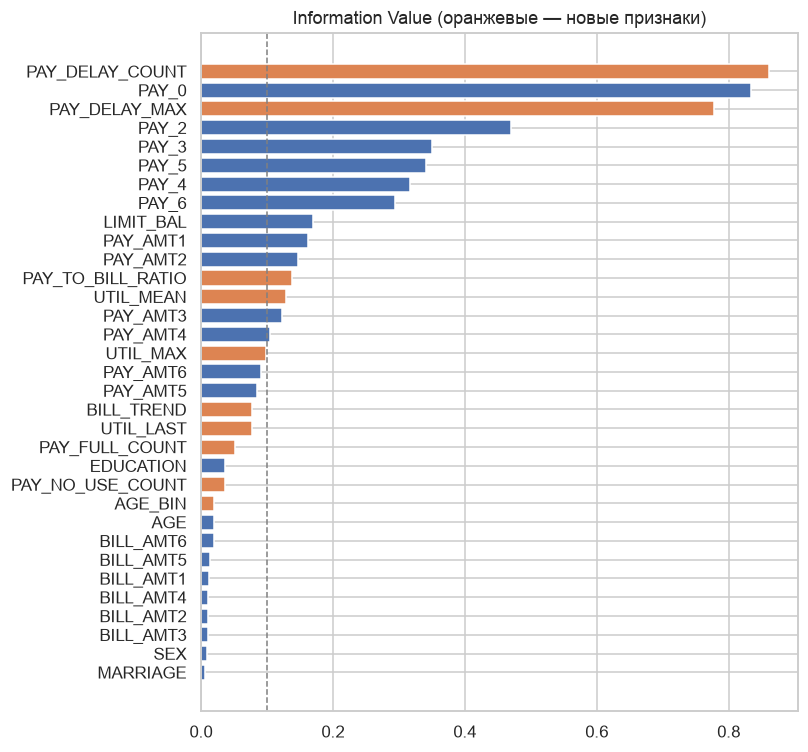

PAY_DELAY_COUNT      0.862
PAY_0                0.833
PAY_DELAY_MAX        0.778
PAY_2                0.469
PAY_3                0.350
PAY_5                0.341
PAY_4                0.316
PAY_6                0.294
LIMIT_BAL            0.170
PAY_AMT1             0.162
PAY_AMT2             0.146
PAY_TO_BILL_RATIO    0.139
dtype: float64

In [13]:
def information_value(x: pd.Series, y: pd.Series, bins: int = 10) -> float:
    if x.nunique() > bins:
        x = pd.qcut(x.rank(method="first"), bins)
    table = pd.crosstab(x, y) + 0.5  # сглаживание, чтобы не делить на ноль
    good = table[0] / table[0].sum()
    bad = table[1] / table[1].sum()
    return float(((good - bad) * np.log(good / bad)).sum())


features = [c for c in fe.columns if c != TARGET]
iv = pd.Series({c: information_value(fe[c], fe[TARGET]) for c in features}).sort_values()
engineered = set(fe.columns) - set(df.columns)

fig, ax = plt.subplots(figsize=(7, 8))
colors = ["#DD8452" if c in engineered else "#4C72B0" for c in iv.index]
ax.barh(iv.index, iv.values, color=colors)
ax.axvline(0.1, color="grey", ls="--", lw=1)
ax.set_title("Information Value (оранжевые — новые признаки)")
fig.savefig(FIG_DIR / "information_value.png", bbox_inches="tight")
plt.show()
iv.sort_values(ascending=False).round(3).head(12)

- Самый сильный признак — сконструированный `PAY_DELAY_COUNT` (IV 0.86). Он сильнее даже `PAY_0`
  (0.83), потому что учитывает всю историю, а не один месяц.
- Сырые `BILL_AMT*` почти бесполезны (IV ≈ 0.01), а те же суммы в отношении к лимиту (`UTIL_MEAN`)
  дают 0.13, а `PAY_TO_BILL_RATIO` — 0.14. Ради этого feature engineering и делался.
- `SEX` и `MARRIAGE` почти не информативны (IV < 0.01).

IV выше 0.5 по классическим правилам считается «подозрительно сильным» и может указывать на
утечку таргета. Здесь утечки нет: просрочки в прошлых месяцах известны банку до октября.
Поведенческие признаки в скоринге обычно и оказываются самыми сильными.

## Итоги: что идёт в пайплайн

| Наблюдение | Решение |
|---|---|
| Пропусков нет, суммы во float, 35 дубликатов | `prepare`: приведение типов, удаление дублей |
| Коды EDUCATION 0/5/6, MARRIAGE 0 | разрешены в GE suite; в пайплайне сводятся к «другое» |
| Допустимые значения и диапазоны признаков | правила Great Expectations (`src/data/validation.py`) |
| Дефолтов 22% | стратифицированный сплит, ROC-AUC/Gini, порог подбирается на CV |
| U-образная зависимость от возраста | признак `AGE_BIN` |
| История PAY_x — главный сигнал | агрегаты просрочек `PAY_DELAY_*`, `PAY_*_COUNT` |
| Сырые суммы слабые и скоррелированные | относительные признаки `UTIL_*`, `BILL_TREND`, `PAY_TO_BILL_RATIO` |
| Длинные хвосты сумм | `StandardScaler` в пайплайне (важно для логрегрессии) |

Чистка категорий и все новые признаки реализованы как трансформер внутри sklearn Pipeline.
Поэтому модель в API принимает те же 23 исходных поля и преобразует их так же, как при обучении.